###  correspondence validation

In [1]:

from pathlib import Path
import pandas as pd

results_dir = Path("/Volumes/WD_BLACK/Spikes2Slope/opto_results")

master = pd.read_csv(
    results_dir / "master_waveform_features.csv"
)

tagged = master.loc[master["is_opto_candidate"] == True].copy()

region_counts = pd.crosstab(
    tagged["ecephys_structure_acronym"].fillna("missing"),
    tagged["cell_type_label"]
).reindex(columns=["Pvalb", "Sst", "Vip"], fill_value=0)

region_counts["total"] = region_counts.sum(axis=1)

display(region_counts.sort_values("total", ascending=False))

visual_cortex = tagged[
    tagged["ecephys_structure_acronym"]
    .fillna("")
    .str.startswith("VIS")
]

print("All candidate units:", len(tagged))
print("Visual cortex candidates:", len(visual_cortex))
print("Non-visual cortex candidates:", len(tagged) - len(visual_cortex))

print("\nVisual cortex candidates by class:")
display(visual_cortex["cell_type_label"].value_counts())


cell_type_label,Pvalb,Sst,Vip,total
ecephys_structure_acronym,,,,
VISam,58,118,50,226
VISp,55,121,50,226
VISal,76,109,32,217
VISrl,50,59,47,156
VISpm,50,63,20,133
VISl,46,34,30,110
LGd,10,31,18,59


All candidate units: 1127
Visual cortex candidates: 1068
Non-visual cortex candidates: 59

Visual cortex candidates by class:


Sst      504
Pvalb    335
Vip      229
Name: cell_type_label, dtype: int64

### waveform correspondence

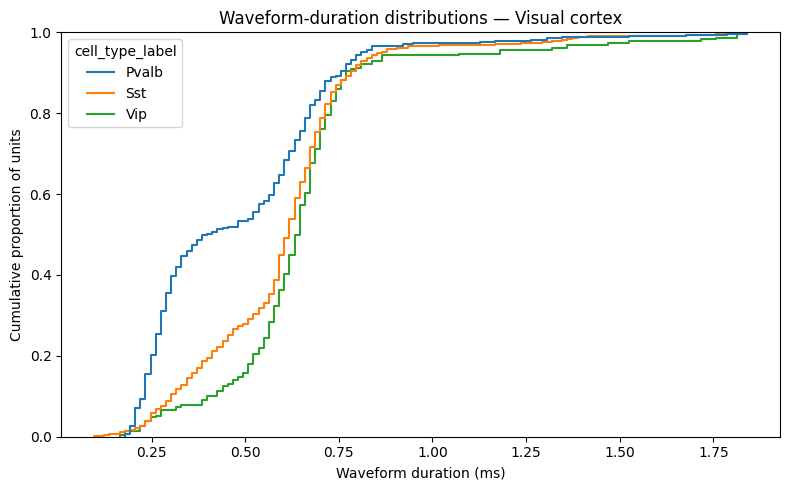

,count,median,mean,std
cell_type_label,,,,
Pvalb,335,0.398,0.479,0.261
Sst,504,0.618,0.597,0.228
Vip,229,0.646,0.651,0.257


In [2]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

order = ["Pvalb", "Sst", "Vip"]

fig, ax = plt.subplots(figsize=(8, 5))

sns.ecdfplot(
    data=visual_cortex,
    x="waveform_duration",
    hue="cell_type_label",
    hue_order=order,
    ax=ax
)

ax.set(
    xlabel="Waveform duration (ms)",
    ylabel="Cumulative proportion of units",
    title="Waveform-duration distributions — Visual cortex"
)

plt.tight_layout()
plt.show()

summary = (
    visual_cortex.groupby("cell_type_label")["waveform_duration"]
    .agg(["count", "median", "mean", "std"])
    .reindex(order)
)

display(summary.round(3))


Among 1,068 optotagging-supported candidates in visual cortex, Pvalb candidates exhibit shorter and more heterogeneous waveform durations than SST and VIP candidates. This is qualitatively consistent with the Allen Institute's report of predominantly fast-spiking Pvalb waveforms and mixed waveform morphologies among SST neurons.

### Session-level waveform correspondence

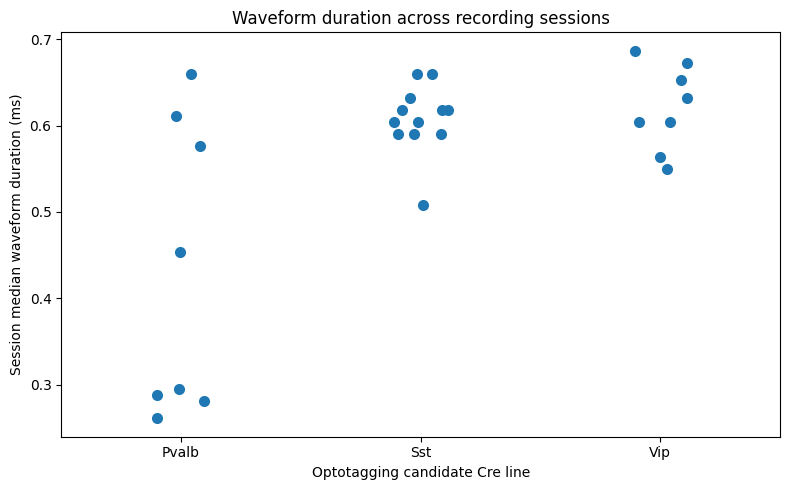

,count,median,min,max
cell_type_label,,,,
Pvalb,8,0.374,0.261,0.659
Sst,12,0.611,0.508,0.659
Vip,8,0.618,0.549,0.687


In [3]:

import matplotlib.pyplot as plt
import seaborn as sns

session_summary = (
    visual_cortex
    .groupby(["ecephys_session_id", "cell_type_label"])
    .agg(
        median_duration=("waveform_duration", "median"),
        n_units=("unit_id", "size")
    )
    .reset_index()
)

order = ["Pvalb", "Sst", "Vip"]

fig, ax = plt.subplots(figsize=(8, 5))

sns.stripplot(
    data=session_summary,
    x="cell_type_label",
    y="median_duration",
    order=order,
    jitter=0.12,
    size=8,
    ax=ax
)

ax.set(
    xlabel="Optotagging candidate Cre line",
    ylabel="Session median waveform duration (ms)",
    title="Waveform duration across recording sessions"
)

plt.tight_layout()
plt.show()

display(
    session_summary
    .groupby("cell_type_label")["median_duration"]
    .agg(["count", "median", "min", "max"])
    .reindex(order)
    .round(3)
)
